# PJ1 RET503 - Praktik COCO (Tahap 1-5)
**Jalankan sel SATU PER SATU dari atas ke bawah** (klik tombol play di kiri sel, atau Shift+Enter).

Aturan penting:
- Runtime harus **T4 GPU** (Runtime -> Change runtime type -> T4 GPU).
- Sel training (06) **dijalankan sekali saja** dan **isinya jangan diubah**.
- Program dosen tidak diubah sama sekali.

## Sel 1 - Identitas (SATU-SATUNYA sel yang boleh kamu edit)

In [1]:
NIM   = "4222411043"
NAMA  = "Lalu Juanda Renaldy"
KELAS = "TRR Malam B"

KELAS_COCO = "bottle banana toothbrush"
JUMLAH     = 200
UBAH_E3    = "imgsz=640"                  # bawaan dosen
MODEL      = "yolo26n"

KERJA = "/content/praktik_coco"           # folder kerja di Colab
DRIVE = "/content/drive/MyDrive/RET503_PJ1"   # folder simpanan di Google Drive
print("OK:", NIM, "|", NAMA, "|", KELAS, "|", KELAS_COCO, "|", UBAH_E3)

OK: 4222411043 | Lalu Juanda Renaldy | TRR Malam B | bottle banana toothbrush | imgsz=640


## Sel 2 - Cek GPU dan pasang Ultralytics

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U ultralytics
import ultralytics, torch
print("Ultralytics:", ultralytics.__version__, "| PyTorch:", torch.__version__, "| GPU:", torch.cuda.is_available())


from ultralytics import YOLO
try:
    YOLO(f"{MODEL}.pt"); YOLO(f"{MODEL}.yaml")
    print(f"Model {MODEL} tersedia.")
except Exception as e:
    print(f"{MODEL} tidak bisa dimuat ({e}). Beralih ke yolov8n.")
    MODEL = "yolov8n"
print("MODEL yang dipakai:", MODEL)

name, memory.total [MiB]
Tesla T4, 15360 MiB
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 11.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.178 | PyTorch: 2.11.0+cu130 | GPU: True
Model yolo26n tersedia.
MODEL yang dipakai: yolo26n


## Sel 3 - Hubungkan Google Drive
Akan muncul jendela izin. **Centang semua izin ("Pilih semua")**, lalu Lanjutkan. Kalau tidak, mount gagal.

In [3]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.makedirs(DRIVE, exist_ok=True)
print("Drive siap:", DRIVE)

Mounted at /content/drive
Drive siap: /content/drive/MyDrive/RET503_PJ1


## Sel 4 - Upload YOLO.zip (program dosen) dan ekstrak

In [4]:
import os, glob, shutil, zipfile
from google.colab import files
os.makedirs(KERJA, exist_ok=True)
%cd /content
print("Klik 'Choose Files' / 'Pilih File', lalu pilih file zip program dosen (YOLO.zip)")
unggah = files.upload()
nama_zip = [n for n in unggah if n.lower().endswith(".zip")][0]
with zipfile.ZipFile(nama_zip) as z:
    z.extractall("/content/program_dosen")

# Isi zip bertingkat (YOLO/YOLO/*.py): cari file .py di mana pun, salin ke folder kerja
for f in glob.glob("/content/program_dosen/**/*.py", recursive=True):
    shutil.copy(f, KERJA)
%cd {KERJA}
!ls -1 *.py

/content
Klik 'Choose Files' / 'Pilih File', lalu pilih file zip program dosen (YOLO.zip)


Saving YOLO (1).zip to YOLO (1).zip
/content/praktik_coco
00_ambil_subset_coco.py
01_cek_anotasi.py
02_yolo_ke_coco.py
03_coco_ke_yolo.py
05_split_dataset_yolo.py
06_latih_bandingkan.py


# TAHAP 1 - Menyiapkan data (program 00, 01, 02, 03)

## Sel 5 - Program 00: ambil subset COCO (mengunduh ±1 GB, beberapa menit)

In [5]:
%cd {KERJA}
!python 00_ambil_subset_coco.py --kelas {KELAS_COCO} --jumlah {JUMLAH}

/content/praktik_coco
Kelas dipilih: ['bottle', 'banana', 'toothbrush'] | jumlah gambar: 200
(Ubah dengan: python 00_ambil_subset_coco.py --kelas <nama1> <nama2> --jumlah <n>)

Mengunduh http://images.cocodataset.org/zips/val2017.zip ... (bisa beberapa menit)
Mengekstrak val2017.zip ...
Mengunduh http://images.cocodataset.org/annotations/annotations_trainval2017.zip ... (bisa beberapa menit)
Mengekstrak annotations_trainval2017.zip ...
Kelas baru      : 0 = bottle, 1 = banana, 2 = toothbrush
Gambar berobjek : 200
Gambar latar    : 20
Jumlah kotak    : bottle 412, banana 163, toothbrush 33
Siap di dataset_yolo/ -> lanjutkan dengan: python 01_cek_anotasi.py dataset_yolo


## Sel 6 - Program 01: cek anotasi

In [6]:
%cd {KERJA}
!python 01_cek_anotasi.py dataset_yolo

/content/praktik_coco
Gambar          : 220
Tanpa file label: 0
Label kosong    : 20 (gambar latar tanpa objek)
Jumlah kotak per kelas:
  bottle    : 412
  banana    : 163
  toothbrush: 33

40 masalah ditemukan:
  [!] 000000008021.txt baris 1: kotak sangat kecil (8x18 px)
  [!] 000000008021.txt baris 2: kotak sangat kecil (8x17 px)
  [!] 000000008021.txt baris 3: kotak sangat kecil (6x17 px)
  [!] 000000036494.txt baris 1: kotak sangat kecil (7x23 px)
  [!] 000000036494.txt baris 2: kotak sangat kecil (5x14 px)
  [!] 000000036494.txt baris 3: kotak sangat kecil (4x9 px)
  [!] 000000036494.txt baris 4: kotak sangat kecil (3x12 px)
  [!] 000000109976.txt baris 2: kotak sangat kecil (7x24 px)
  [!] 000000109976.txt baris 4: kotak sangat kecil (7x27 px)
  [!] 000000125778.txt baris 4: kotak sangat kecil (7x36 px)
  [!] 000000140076.txt baris 5: kotak sangat kecil (7x11 px)
  [!] 000000140076.txt baris 8: kotak sangat kecil (5x24 px)
  [!] 000000166918.txt baris 3: kotak sangat kecil (4x17 

## Sel 7 - Cek visual: tampilkan 6 gambar berkotak dari cek_visual/

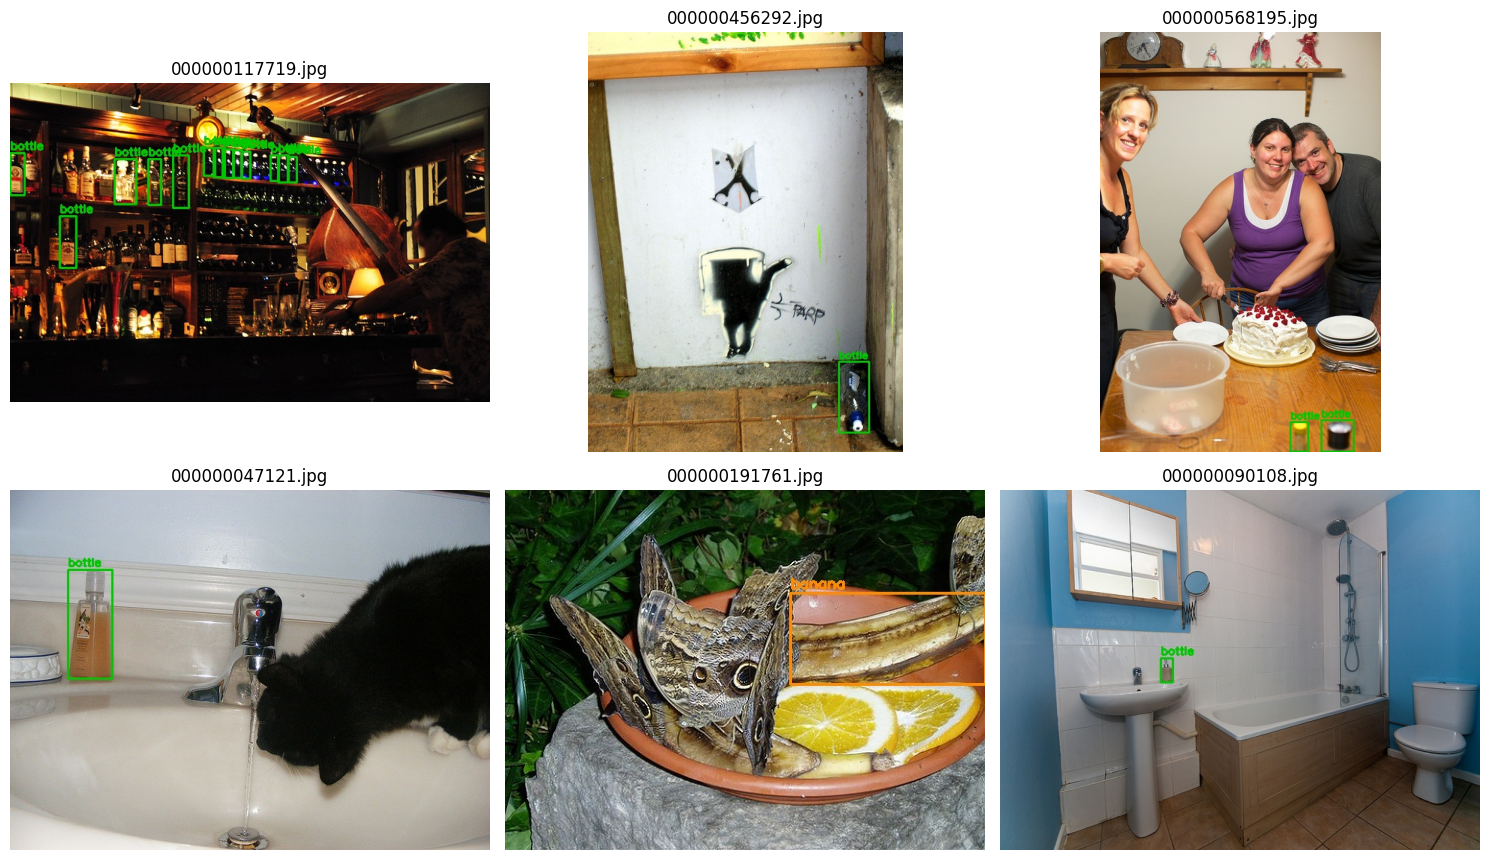

Disimpan juga sebagai cek_visual_contoh.png (untuk README)


In [7]:
import random, cv2, glob, os
import matplotlib.pyplot as plt
os.chdir(KERJA)
# pilih gambar yang punya label (bukan latar), supaya kotaknya terlihat
berlabel = [p for p in sorted(glob.glob("dataset_yolo/cek_visual/*"))
            if os.path.getsize(f"dataset_yolo/labels/{os.path.splitext(os.path.basename(p))[0]}.txt") > 0]
random.seed(1)
contoh = random.sample(berlabel, min(6, len(berlabel)))
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, p in zip(ax.flat, contoh):
    a.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); a.set_title(os.path.basename(p)); a.axis("off")
plt.tight_layout(); plt.savefig("cek_visual_contoh.png", dpi=80); plt.show()
print("Disimpan juga sebagai cek_visual_contoh.png (untuk README)")

## Sel 8 - Program 02 dan 03: uji konversi dua arah YOLO -> COCO -> YOLO

In [8]:
%cd {KERJA}
!python 02_yolo_ke_coco.py dataset_yolo dataset_yolo/annotations_coco.json
!python 03_coco_ke_yolo.py dataset_yolo/annotations_coco.json hasil_balik

# Bandingkan label asli dengan label hasil bolak-balik
import os, glob
beda, total, maks = 0, 0, 0.0
for asli in sorted(glob.glob("dataset_yolo/labels/*.txt")):
    balik = os.path.join("hasil_balik/labels", os.path.basename(asli))
    A = [l.split() for l in open(asli).read().splitlines() if l.strip()]
    B = [l.split() for l in open(balik).read().splitlines() if l.strip()] if os.path.exists(balik) else []
    total += 1
    if len(A) != len(B) or any(a[0] != b[0] for a, b in zip(A, B)):
        beda += 1; continue
    for a, b in zip(A, B):
        maks = max(maks, *(abs(float(x) - float(y)) for x, y in zip(a[1:], b[1:])))
print(f"File label dibandingkan : {total}")
print(f"File yang berbeda       : {beda}")
print(f"Selisih koordinat maks  : {maks:.6f}  (kecil = hanya pembulatan)")
print("KONVERSI DUA ARAH LOLOS" if beda == 0 and maks < 1e-3 else "PERIKSA: ada perbedaan")

/content/praktik_coco
220 gambar, 608 kotak, 3 kategori -> dataset_yolo/annotations_coco.json
220 file label dibuat di hasil_balik/labels
File label dibandingkan : 220
File yang berbeda       : 0
Selisih koordinat maks  : 0.000000  (kecil = hanya pembulatan)
KONVERSI DUA ARAH LOLOS


# TAHAP 2 - Membagi data (program 05)

## Sel 9 - Program 05: train/val/test + data.yaml

In [9]:
%cd {KERJA}
!python 05_split_dataset_yolo.py dataset_yolo dataset_v1
!cat dataset_v1/data.yaml

/content/praktik_coco
train: 154 gambar
val  : 44 gambar
test : 22 gambar

data.yaml dibuat di dataset_v1/data.yaml
path: /content/praktik_coco/dataset_v1
train: images/train
val: images/val
test: images/test
names:
  0: bottle
  1: banana
  2: toothbrush


# TAHAP 3-5 - Training E1, E2, E3 (program 06)
## Sel 10 - TRAINING. JALANKAN SEKALI SAJA. JANGAN UBAH ISINYA.
`{NIM}` `{NAMA}` `{MODEL}` `{UBAH_E3}` adalah variabel dari Sel 1 dan 2, **jangan diganti teks**.
Butuh waktu (perkiraan puluhan menit). Biarkan tab Colab tetap terbuka.

In [10]:
%cd {KERJA}
import os
if os.path.exists(f"hasil_praktik_{NIM}.txt"):
    print("Training SUDAH pernah selesai. Tidak dijalankan ulang. Lanjut ke Sel 11.")
else:
    !python 06_latih_bandingkan.py --nim {NIM} --nama "{NAMA}" --model {MODEL} --ubah {UBAH_E3}

/content/praktik_coco

=== E1_pretrained: yolo26n.pt | pretrained=True | pengaturan dasar ===
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0

## Sel 11 - Tampilkan hasil_praktik (tabel E1/E2/E3 + test)

In [11]:
%cd {KERJA}
!cat hasil_praktik_{NIM}.txt
!cat hasil_praktik_{NIM}.csv

/content/praktik_coco
  PRAKTIK TERPADU MINGGU 4-7 - RET503
  NIM / Nama    : 4222411043 / Lalu Juanda Renaldy
  Waktu         : 16-10-2026 10:08:45
  Komputer/user : 4e360cef27ca / root
  Dataset       : dataset_v1  (sidik jari label: 3262B29C99F5)
  Pengaturan    : model yolo26n, epochs 30, imgsz 416, batch 16
  Eksperimen     Perubahan        mAP50  mAP50-95      P      R     ms   menit
  E1_pretrained  -                0.330     0.167  0.238  0.440    7.4     1.8
  E2_scratch     -                0.000     0.000  0.001  0.078    4.3     1.5
  E3_tuning      imgsz=640        0.378     0.219  0.769  0.307   10.0     1.9
  Model terpilih (mAP50-95 val tertinggi): E3_tuning
  Hasil di data TEST (sekali saja)       : mAP50 0.823 | mAP50-95 0.630
eksperimen,perubahan,pretrained,mAP50,mAP50-95,precision,recall,inferensi_ms,waktu_latih_menit,imgsz,bobot
E1_pretrained,-,True,0.3295,0.1673,0.2384,0.4395,7.37,1.77,416,/content/praktik_coco/hasil_praktik/E1_pretrained/weights/best.pt
E2_scratc

## Sel 12 - Tampilkan results.png E1, E2, E3

============================== E1_pretrained


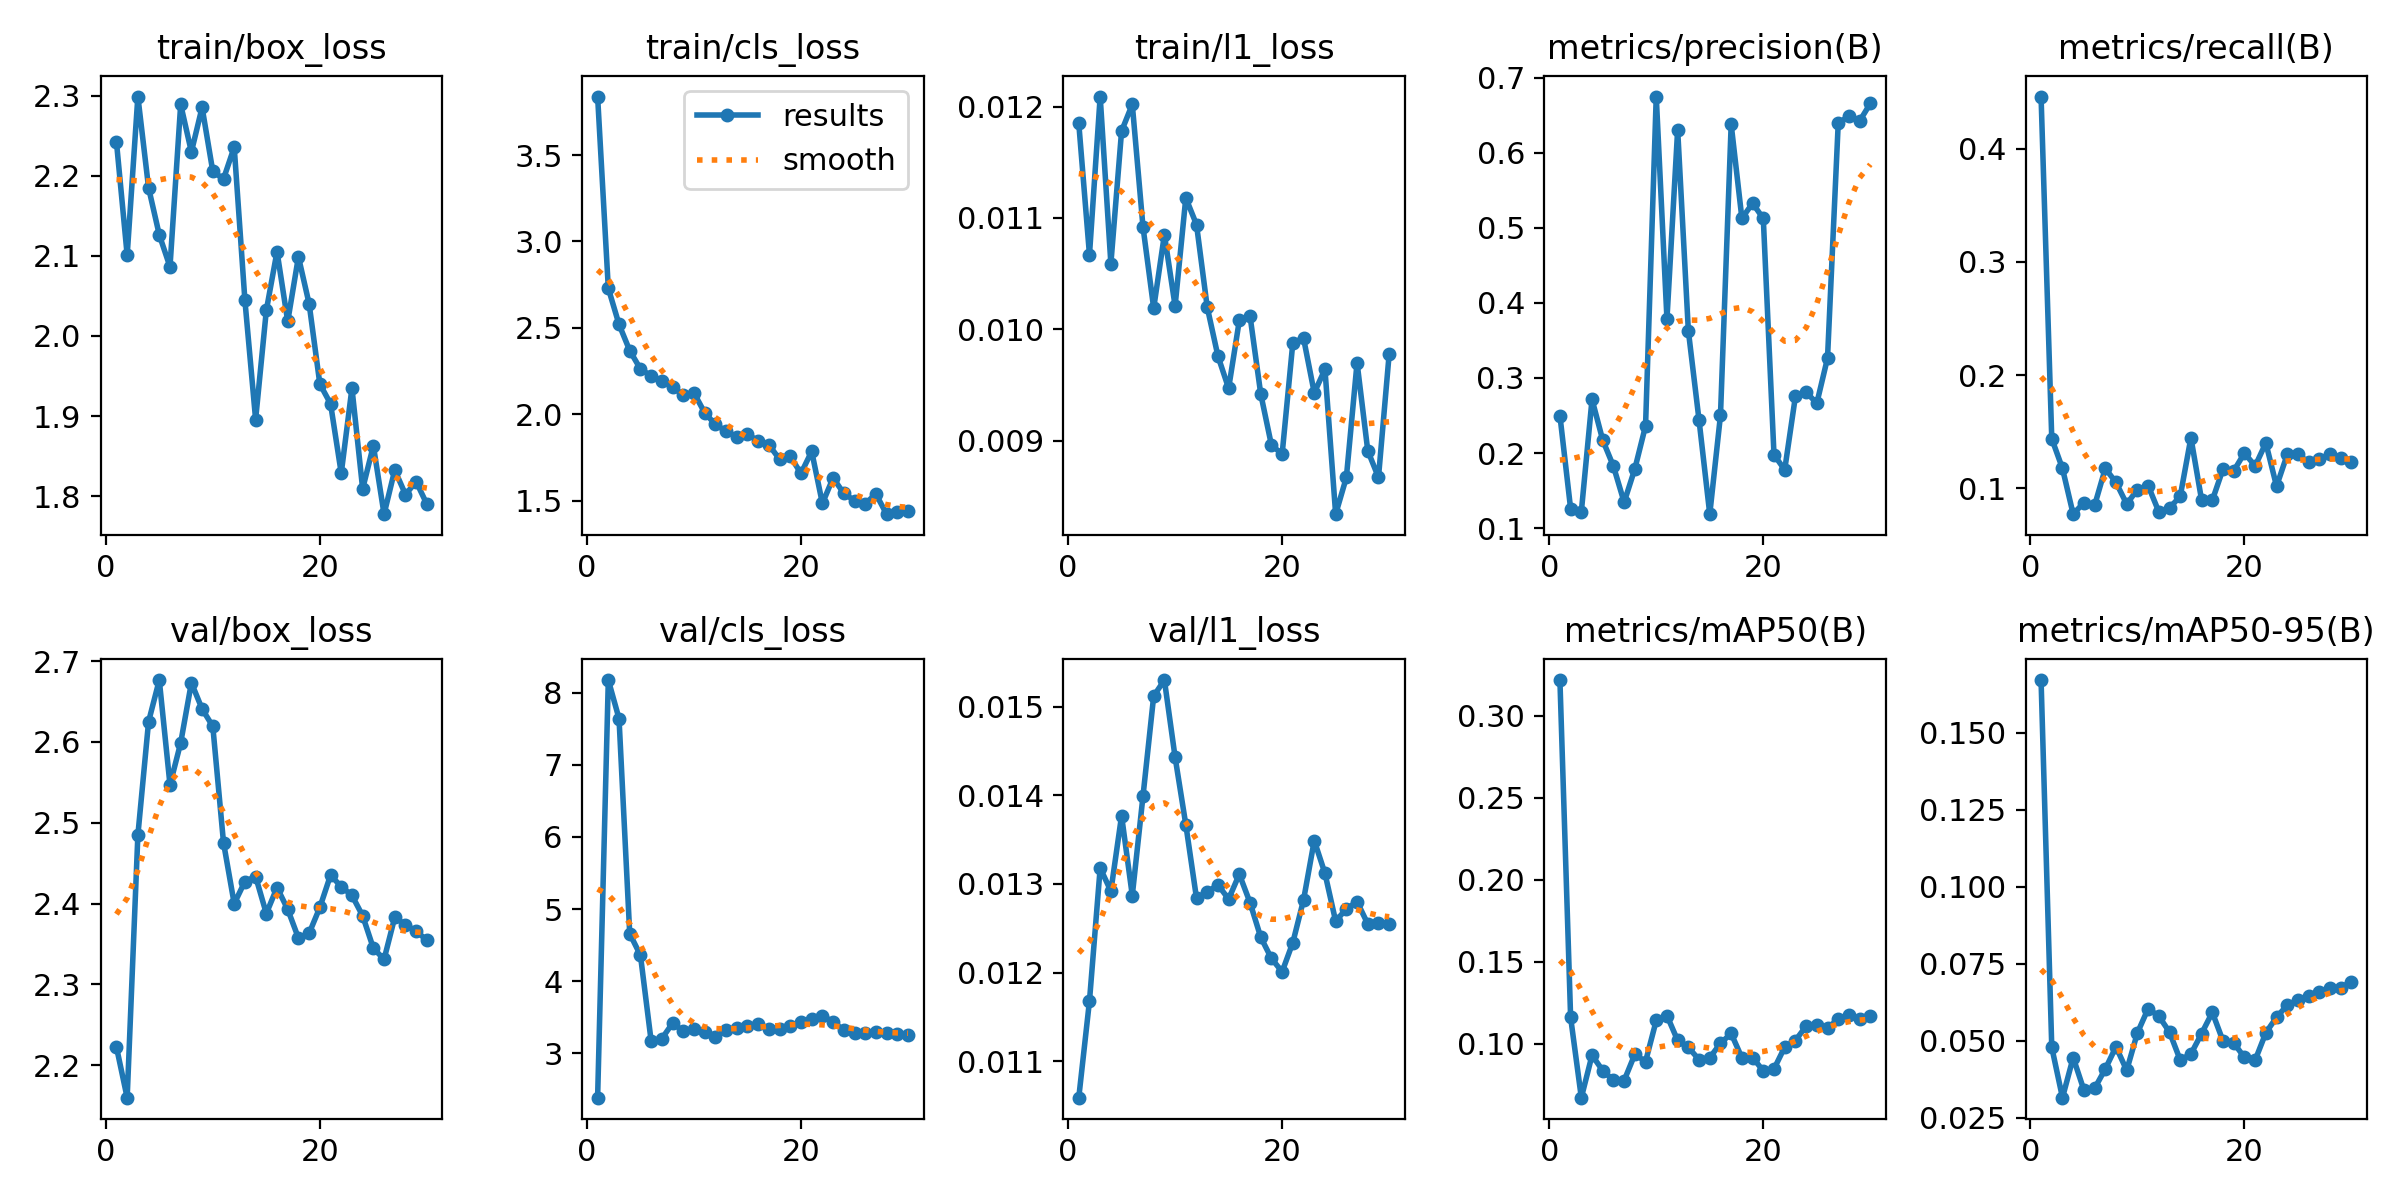

============================== E2_scratch


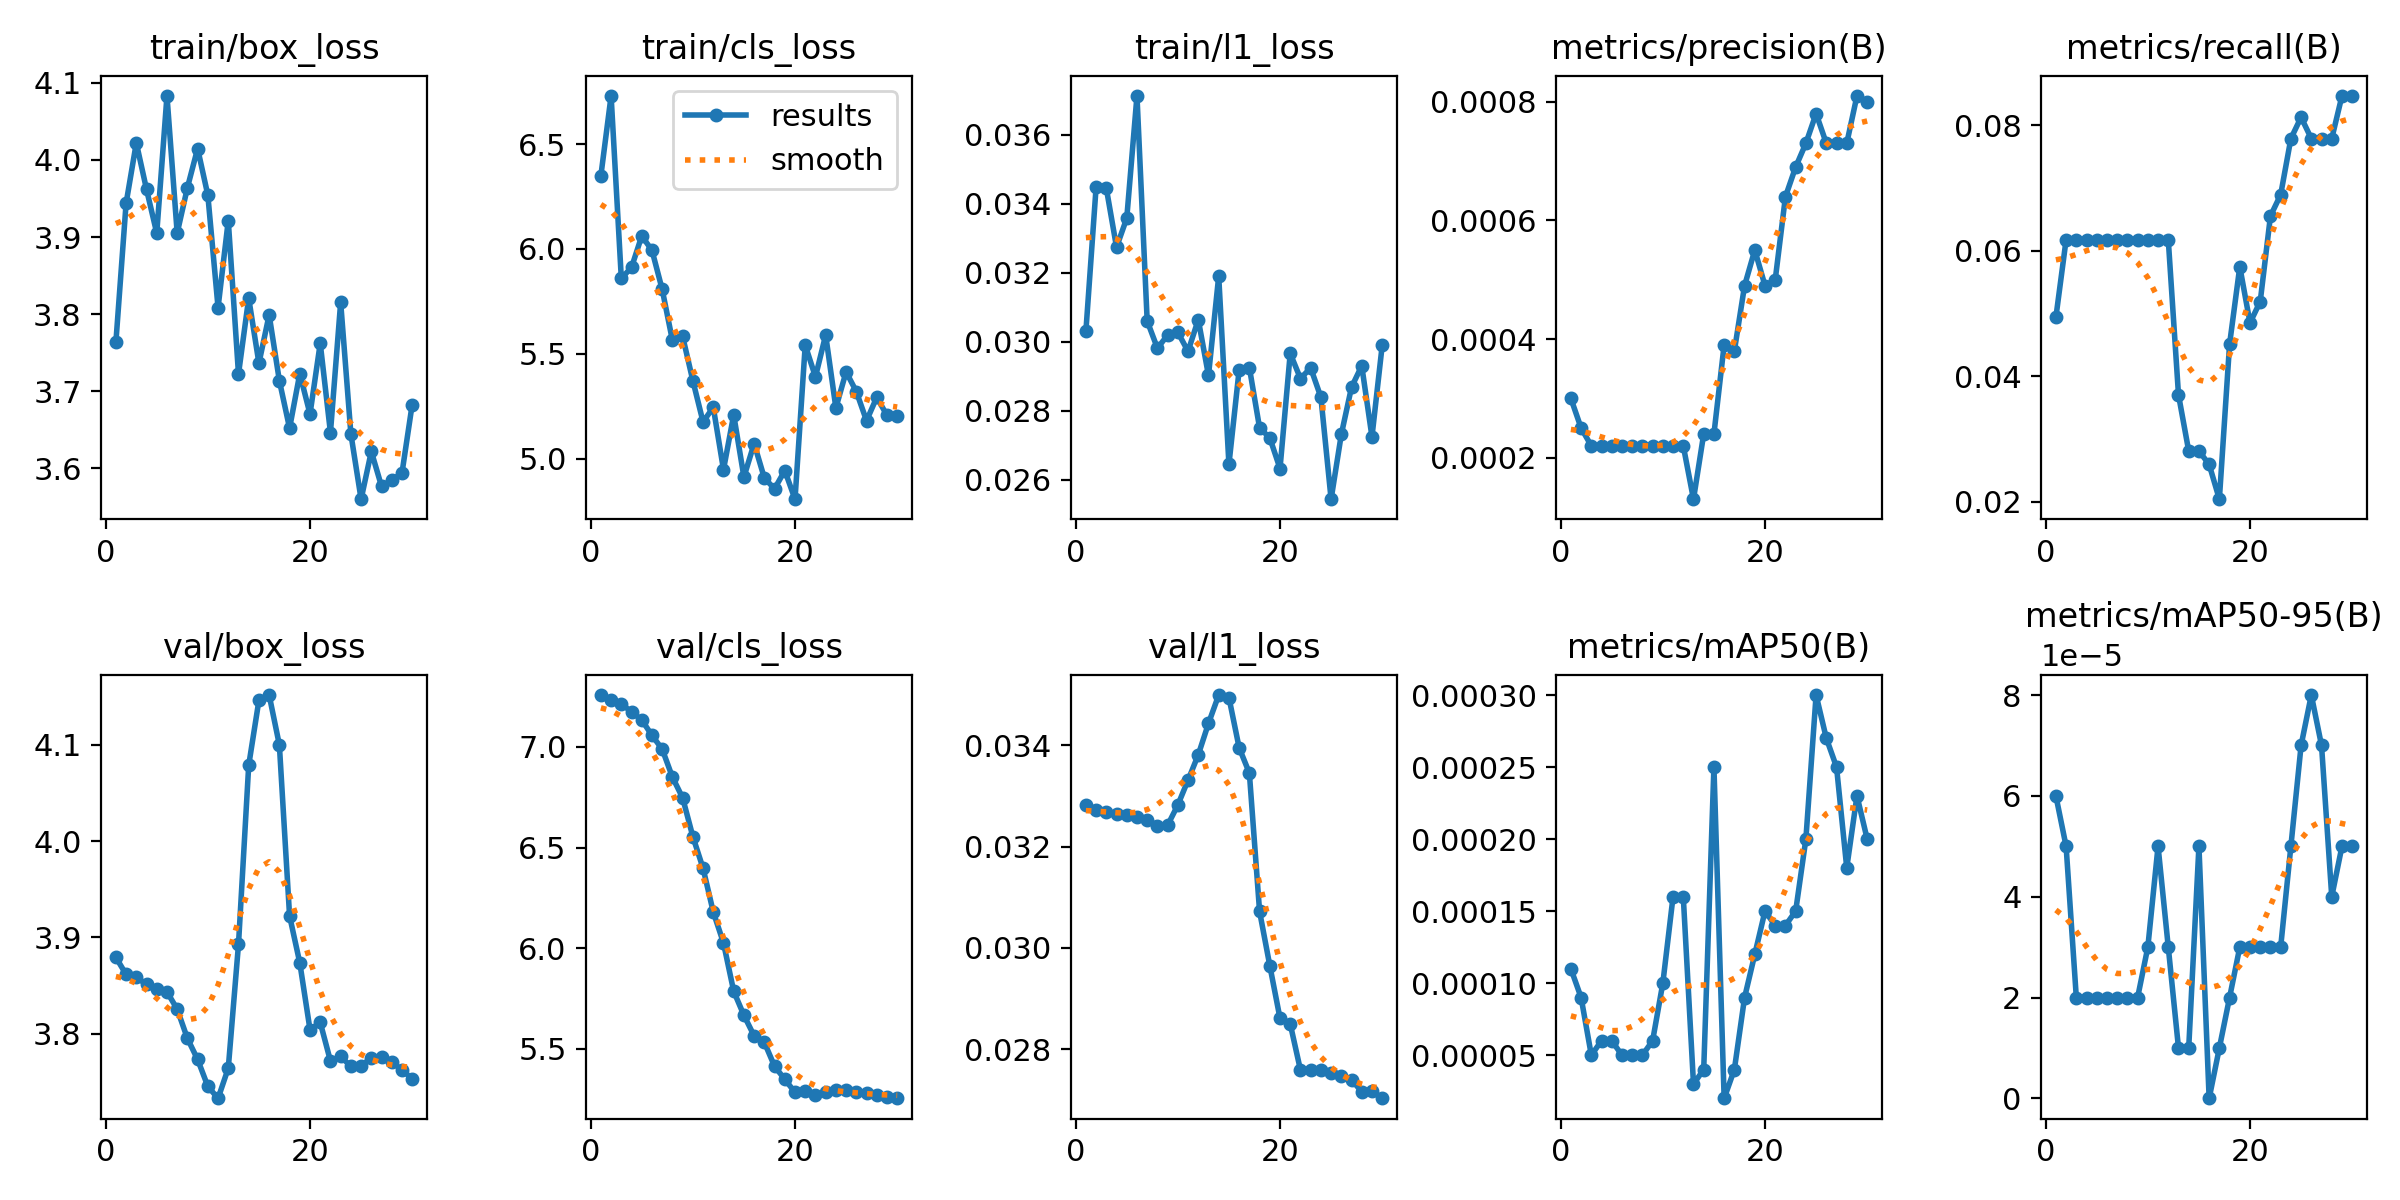

============================== E3_tuning


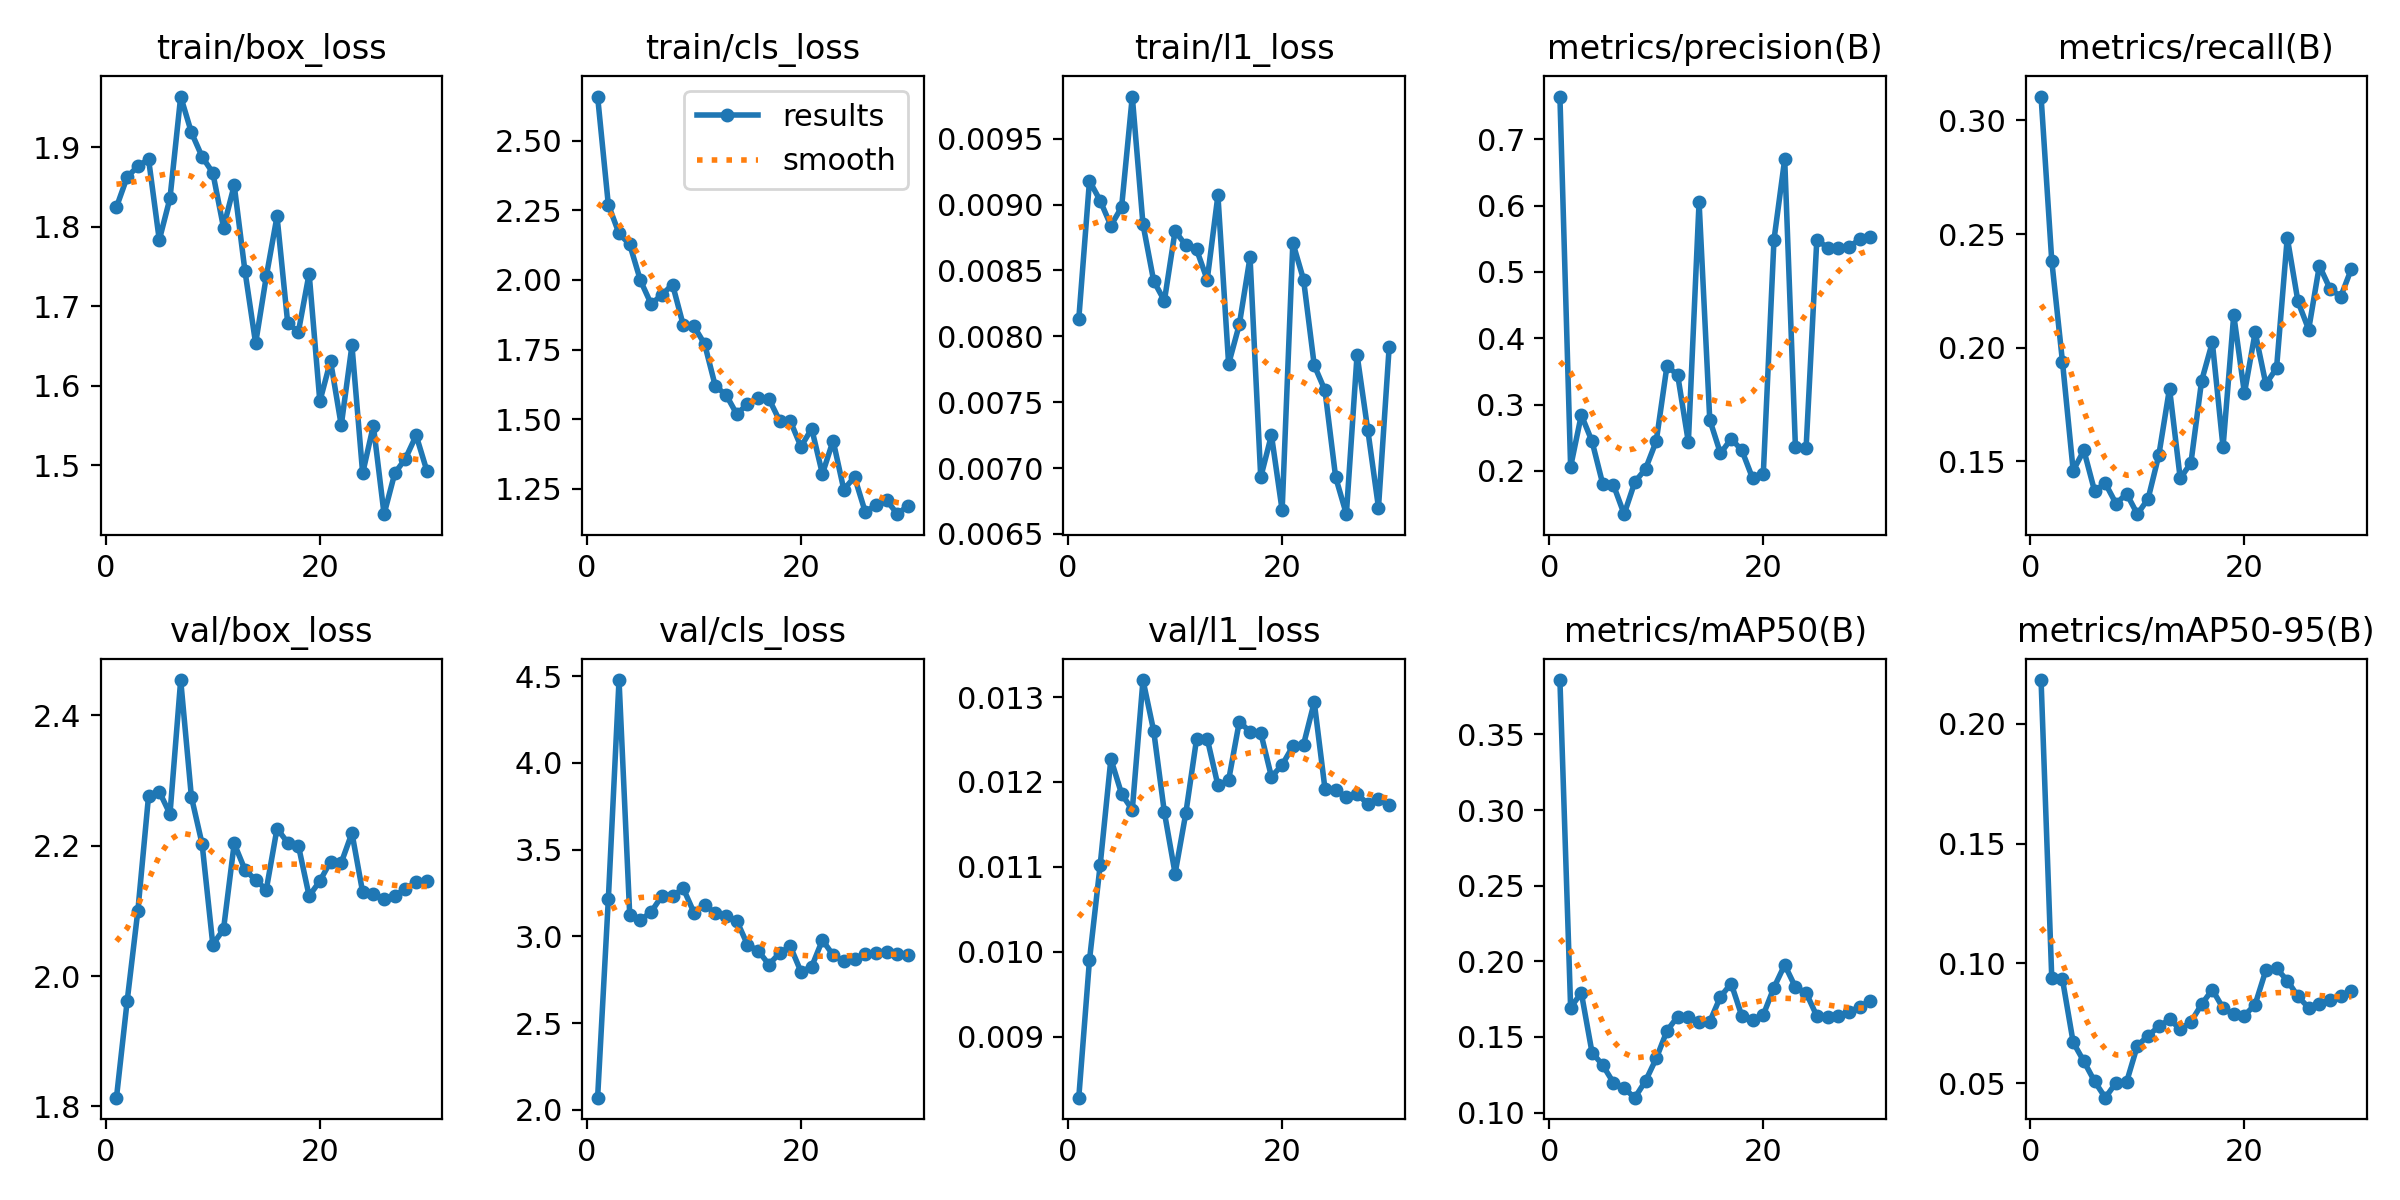

In [12]:
from IPython.display import Image, display
import os
for e in ["E1_pretrained", "E2_scratch", "E3_tuning"]:
    p = f"{KERJA}/hasil_praktik/{e}/results.png"
    print("=" * 30, e)
    display(Image(p, width=1000)) if os.path.exists(p) else print("tidak ada:", p)

## Sel 13 - AP per kelas (data VAL) untuk E1 dan E3, + model terpilih di TEST

In [13]:
import os, glob, csv
from collections import Counter
from ultralytics import YOLO
os.chdir(KERJA)
DATA = "dataset_v1/data.yaml"
NAMES = [l.split(":", 1)[1].strip() for l in open(DATA).read().splitlines() if l.startswith("  ") and ":" in l]

def jumlah_kotak(split):
    c = Counter()
    for f in glob.glob(f"dataset_v1/labels/{split}/*.txt"):
        for l in open(f).read().splitlines():
            if l.strip(): c[int(l.split()[0])] += 1
    return c

def ap_per_kelas(eksperimen, split, imgsz):
    m = YOLO(f"hasil_praktik/{eksperimen}/weights/best.pt").val(
        data=DATA, split=split, imgsz=imgsz, batch=16, plots=False, verbose=False,
        project="/content/val_sementara", name=f"{eksperimen}_{split}", exist_ok=True)
    n = jumlah_kotak(split)
    idx = [int(x) for x in getattr(m, "ap_class_index", m.box.ap_class_index)]
    hasil = []
    for i, k in enumerate(NAMES):
        if i in idx:
            j = idx.index(i)
            hasil.append([eksperimen, split, k, n[i], round(float(m.box.ap50[j]), 4), round(float(m.box.ap[j]), 4)])
        else:
            hasil.append([eksperimen, split, k, n[i], "-", "-"])   # kelas tidak muncul di split ini
    return hasil

imgsz_E3 = int(UBAH_E3.split("=")[1]) if UBAH_E3.startswith("imgsz=") else 416
semua = ap_per_kelas("E1_pretrained", "val", 416) + ap_per_kelas("E3_tuning", "val", imgsz_E3)

# Model terpilih dibaca dari laporan program 06 (bukan memilih ulang), lalu dirinci per kelas di TEST
teks = open(f"hasil_praktik_{NIM}.txt").read()
terpilih = teks.split("Model terpilih (mAP50-95 val tertinggi):")[1].split()[0]
imgsz_t = imgsz_E3 if terpilih == "E3_tuning" else 416
semua += ap_per_kelas(terpilih, "test", imgsz_t)

kepala = ["eksperimen", "split", "kelas", "jumlah_kotak", "AP50", "AP50-95"]
print(f"{kepala[0]:15s}{kepala[1]:6s}{kepala[2]:12s}{kepala[3]:>13s}{kepala[4]:>8s}{kepala[5]:>9s}")
for r in semua:
    print(f"{r[0]:15s}{r[1]:6s}{r[2]:12s}{r[3]:>13}{str(r[4]):>8s}{str(r[5]):>9s}")
with open(f"ap_per_kelas_{NIM}.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(kepala); w.writerows(semua)
print(f"\nTersimpan: ap_per_kelas_{NIM}.csv  | model terpilih: {terpilih}")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3762.9±801.9 MB/s, size: 236.7 KB)
val: Scanning /content/praktik_coco/dataset_v1/labels/val.cache... 44 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 5.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.6it/s 0.8s
                   all         44        128      0.238       0.44      0.329      0.167
Speed: 0.6ms preprocess, 7.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4499.3±1432.2 MB/s, size: 217.3 KB)
val: Scanning /content/praktik_coco/dataset_v1/labels/val

## Sel 14 - Confusion matrix E1 dan E3 (bahan analisis)

============================== E1_pretrained


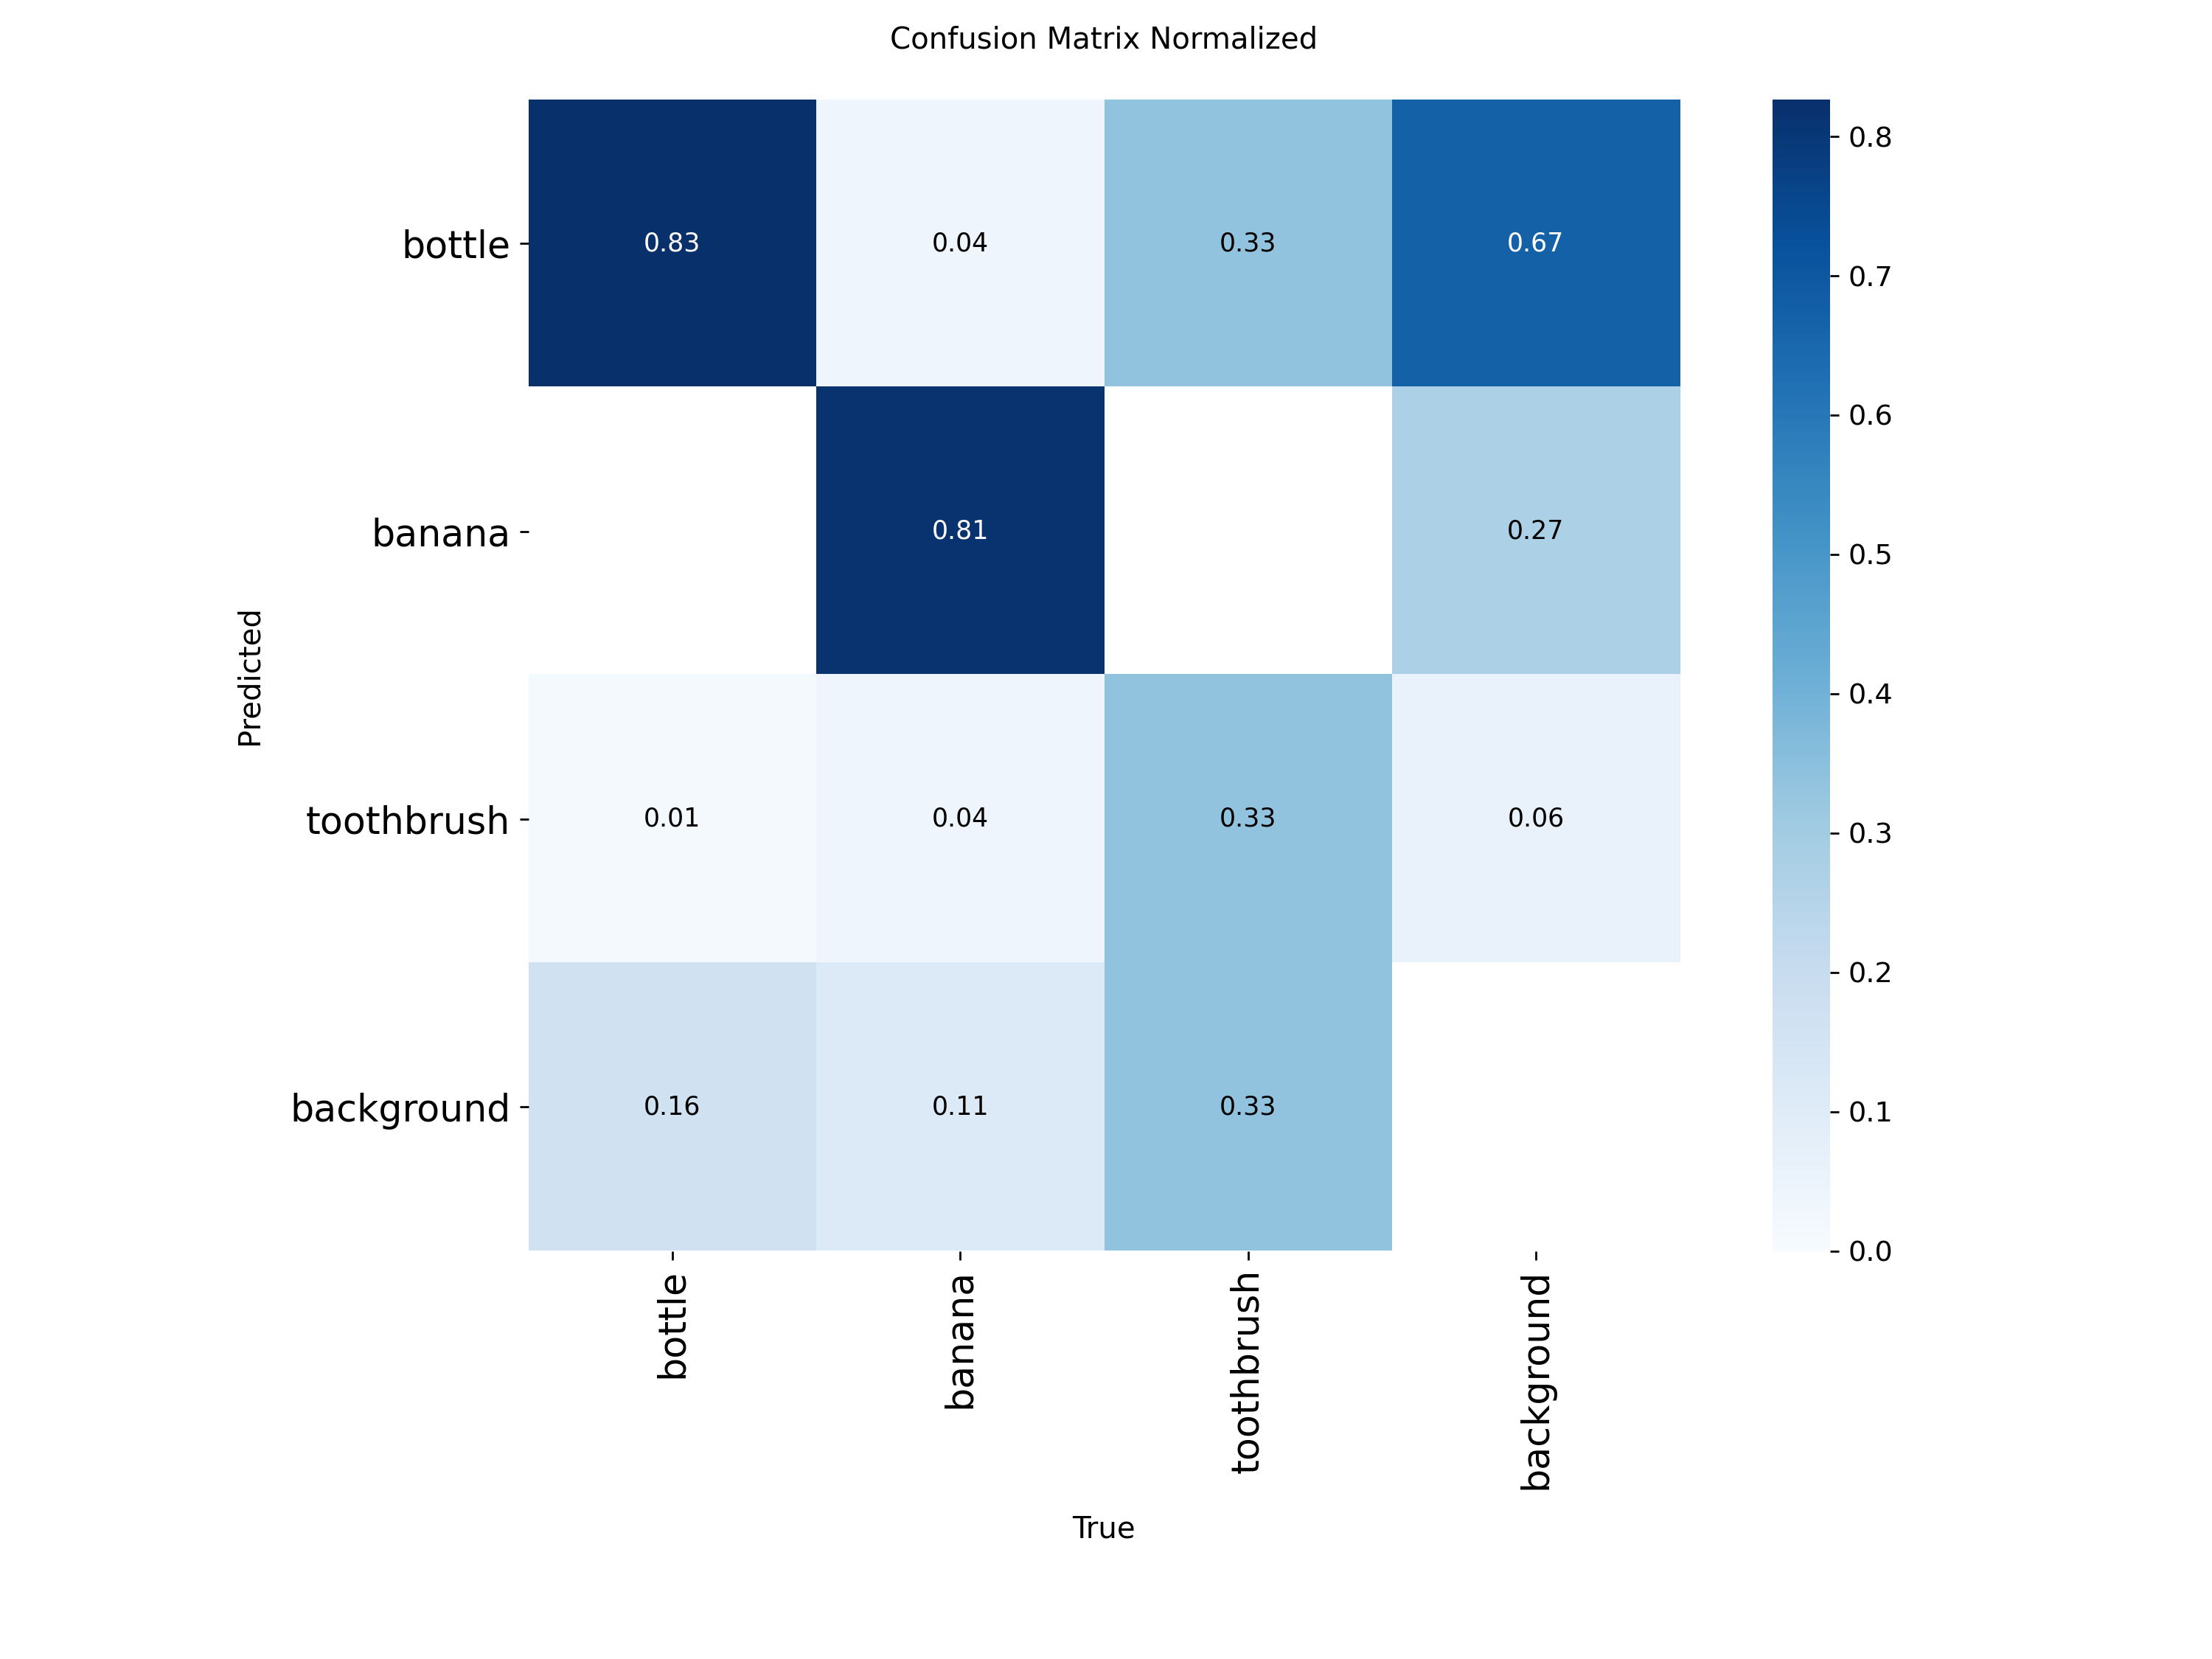

============================== E3_tuning


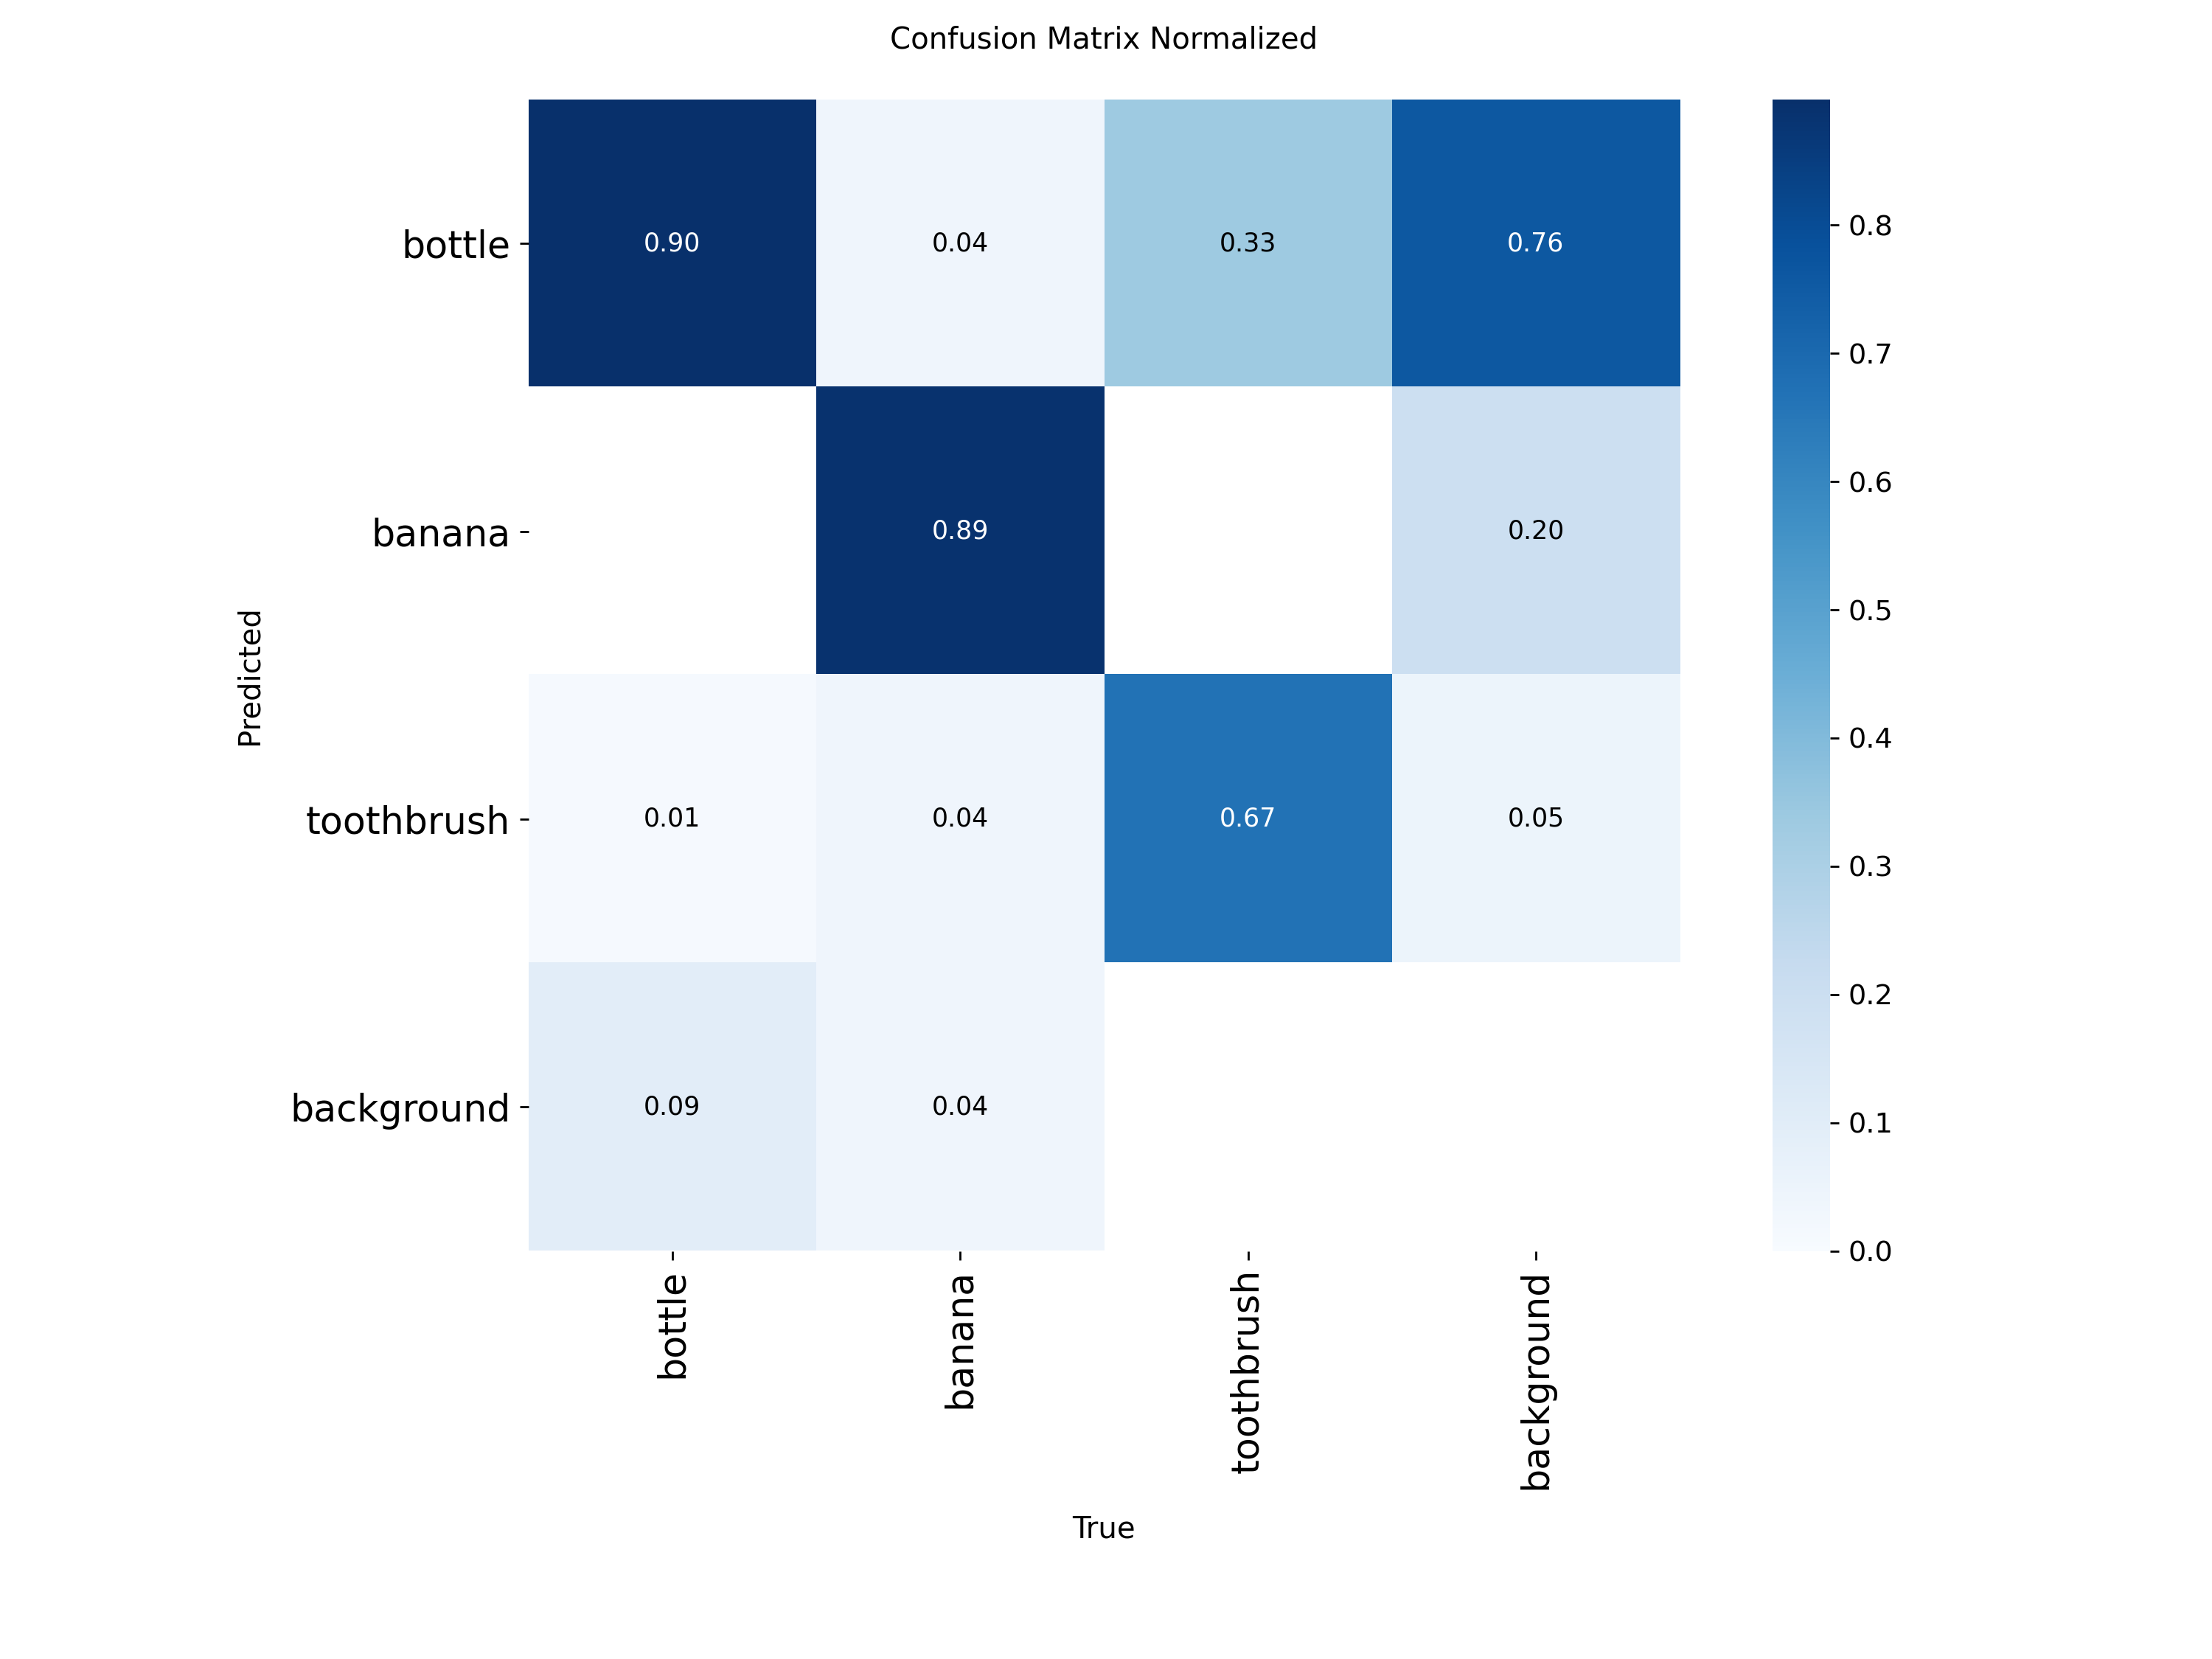

In [14]:
from IPython.display import Image, display
import os
for e in ["E1_pretrained", "E3_tuning"]:
    p = f"{KERJA}/hasil_praktik/{e}/confusion_matrix_normalized.png"
    if not os.path.exists(p): p = p.replace("_normalized", "")
    print("=" * 30, e); display(Image(p, width=600)) if os.path.exists(p) else print("tidak ada:", p)

## Sel 15 - Zip hasil, simpan ke Drive, dan unduh
- `github_coco_<NIM>.zip` -> **kecil**, isinya untuk diupload ke GitHub (tanpa bobot .pt dan tanpa dataset).
- `lengkap_coco_<NIM>.zip` -> **besar**, berisi dataset + bobot, hanya disimpan di Google Drive (nanti dibagikan lewat link).

In [15]:
import os, shutil, glob, zipfile
os.chdir(KERJA)

def zip_folder(nama_zip, daftar, kecualikan=()):
    with zipfile.ZipFile(nama_zip, "w", zipfile.ZIP_DEFLATED) as z:
        for item in daftar:
            path_list = [item] if os.path.isfile(item) else glob.glob(f"{item}/**/*", recursive=True)
            for p in path_list:
                if os.path.isfile(p) and not any(k in p for k in kecualikan):
                    z.write(p)
    print(f"{nama_zip}: {os.path.getsize(nama_zip)/1e6:.1f} MB")

kecil = [f"hasil_praktik_{NIM}.txt", f"hasil_praktik_{NIM}.csv", f"ap_per_kelas_{NIM}.csv",
         "cek_visual_contoh.png", "dataset_v1/data.yaml", "hasil_praktik"]
zip_folder(f"github_coco_{NIM}.zip", kecil, kecualikan=("/weights/",))
zip_folder(f"lengkap_coco_{NIM}.zip", [k for k in kecil if k != "dataset_v1/data.yaml"] + ["dataset_yolo", "dataset_v1"])

for z in [f"github_coco_{NIM}.zip", f"lengkap_coco_{NIM}.zip"]:
    shutil.copy(z, DRIVE)
print("Tersalin ke Google Drive:", DRIVE)

from google.colab import files
files.download(f"github_coco_{NIM}.zip")

github_coco_4222411043.zip: 18.0 MB
lengkap_coco_4222411043.zip: 142.7 MB
Tersalin ke Google Drive: /content/drive/MyDrive/RET503_PJ1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>